# 🛒 SmartBasket: Market Basket Analysis & Product Recommendation System
**Course:** Data Mining Lab Final Project  |  **Team:** 4 Members  
**Dataset:** The Bread Basket (bakery transaction logs)  |  **Core algorithm:** Apriori (frequent itemsets → association rules)

| Member | Module | Main deliverable |
|---|---|---|
| **Member 1** | Data pipeline & preprocessing | Clean one-hot basket matrix |
| **Member 2** | Apriori & rule mining engine | Frequent itemsets + strong rules |
| **Member 3** | Recommendation engine & visual diagnostics | `recommend_items()` + charts |
| **Member 4** | Evaluation, export & Streamlit UI | Hit-rate evaluation, CSV, `app.py` |

**Run order:** run all cells top to bottom (*Runtime → Run all*). Every module depends on the one before it.

## ⚙️ 0. Setup & Global Configuration
All thresholds live in one place, so the whole team changes them consistently.

In [1]:
# Install mlxtend only if it is missing
try:
    import mlxtend
except ImportError:
    %pip install -q mlxtend

import os, random, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules

# ---------- Global configuration ----------
SEED        = 42
MIN_SUPPORT = 0.01   # itemset must appear in >= 1% of baskets
MIN_CONF    = 0.20   # P(consequent | antecedent) >= 20%
MIN_LIFT    = 1.0    # > 1 means positive association
TOP_N       = 3      # recommendations shown per cart

DATASET_FILE = "bread_basket.csv"
DATASET_URLS = [   # tried in order; first one that works is used
    "https://raw.githubusercontent.com/viktree/curly-octo-chainsaw/master/BreadBasket_DMS.csv",
]

random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("✔ Environment ready.")

✔ Environment ready.


---
## 👤 Member 1 — Data Ingestion, Cleaning & Basket Matrix
**Objective:** turn raw transaction logs into a clean one-hot (True/False) basket × item matrix that Apriori can read.

**Steps**
1. Load the dataset (several mirrors are tried; a local copy is used if present).
2. Validate columns and clean: drop missing rows, normalise text, remove placeholder items (`none`, `adjustment`).
3. Group by `Transaction` and one-hot encode the items (a repeated item in one basket still counts as one).
4. Keep only baskets with **≥ 2 items** — a single-item basket cannot produce a co-purchase pair.

**Defense pitch:** *"I built the ETL module: I loaded and validated the logs, removed noisy placeholder items, and converted the relational table into a one-hot basket matrix for Apriori."*

In [2]:
# 1. Load (local file first, then download from mirrors)
def load_dataset():
    if not os.path.exists(DATASET_FILE):
        for url in DATASET_URLS:
            try:
                urllib.request.urlretrieve(url, DATASET_FILE)
                print(f"✔ Downloaded dataset from {url}")
                break
            except Exception as e:
                print(f"✘ Mirror failed ({e})")
        else:
            raise FileNotFoundError(
                f"Could not download the dataset. Upload '{DATASET_FILE}' manually "
                "(Kaggle: 'The Bread Basket') and re-run.")
    return pd.read_csv(DATASET_FILE)

df_raw = load_dataset()
df_raw.columns = df_raw.columns.str.strip().str.capitalize()
assert {"Transaction", "Item"} <= set(df_raw.columns), f"Unexpected columns: {list(df_raw.columns)}"
print(f"Raw records: {len(df_raw):,}  |  columns: {list(df_raw.columns)}")

# 2. Clean
PLACEHOLDERS = {"none", "adjustment", "missing", ""}
df_clean = df_raw.dropna(subset=["Transaction", "Item"]).copy()
df_clean["Item"] = df_clean["Item"].astype(str).str.strip().str.lower()
df_clean = df_clean[~df_clean["Item"].isin(PLACEHOLDERS)]

print(f"Records after cleaning : {len(df_clean):,}  (removed {len(df_raw) - len(df_clean):,})")
print(f"Unique transactions    : {df_clean['Transaction'].nunique():,}")
print(f"Distinct items         : {df_clean['Item'].nunique():,}")

# 3. One-hot basket matrix (True/False)
basket_matrix_all = pd.crosstab(df_clean["Transaction"], df_clean["Item"]).gt(0)

# 4. Keep multi-item baskets only
basket_size = basket_matrix_all.sum(axis=1)
basket_matrix = basket_matrix_all[basket_size > 1]

print(f"\nSingle-item baskets removed : {(basket_size == 1).sum():,}")
print(f"✔ Basket matrix ready       : {basket_matrix.shape[0]:,} baskets × {basket_matrix.shape[1]} items")
print(f"  Average basket size       : {basket_matrix.sum(axis=1).mean():.2f} items")
basket_matrix.head()

Raw records: 21,293  |  columns: ['Date', 'Time', 'Transaction', 'Item']
Records after cleaning : 20,506  (removed 787)
Unique transactions    : 9,464
Distinct items         : 93

Single-item baskets removed : 3,947
✔ Basket matrix ready       : 5,517 baskets × 93 items
  Average basket size       : 2.71 items


Item,afternoon with the baker,alfajores,argentina night,art tray,bacon,baguette,bakewell,bare popcorn,basket,bowl nic pitt,...,the bart,the nomad,tiffin,toast,truffles,tshirt,valentine's card,vegan feast,vegan mincepie,victorian sponge
Transaction,,,,,,,,,,,,,,,,,,,,,
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


---
## 👤 Member 2 — Apriori Algorithm & Association Rule Mining
**Objective:** find frequent itemsets and extract strong rules.

**Key ideas**
- **Support** = fraction of baskets containing the itemset.  
- **Confidence** (A→B) = P(B | A) = support(A∪B) / support(A).  
- **Lift** = confidence / support(B). Lift > 1 means A and B are bought together *more than chance*.  
- **Apriori property:** every subset of a frequent itemset is frequent, so candidates with an infrequent subset are pruned.

**Thresholds:** support ≥ 0.01, confidence ≥ 0.20, lift > 1.0

**Defense pitch:** *"I implemented the mining engine with Apriori, pruned itemsets below 1% support, and kept only rules with lift > 1 and confidence ≥ 20% to avoid spurious correlations."*

In [3]:
def mine_rules(matrix, min_support=MIN_SUPPORT, min_conf=MIN_CONF, min_lift=MIN_LIFT):
    # Run Apriori + rule generation; returns (frequent_itemsets, rules).
    freq = apriori(matrix, min_support=min_support, use_colnames=True)
    freq["length"] = freq["itemsets"].apply(len)
    if len(freq) == 0:
        return freq, pd.DataFrame()

    # mlxtend >= 0.23 needs num_itemsets; older versions do not accept it
    try:
        r = association_rules(freq, num_itemsets=len(matrix), metric="lift", min_threshold=min_lift)
    except TypeError:
        r = association_rules(freq, metric="lift", min_threshold=min_lift)

    r = r[(r["confidence"] >= min_conf) & (r["lift"] > min_lift)].copy()
    r["antecedents_str"] = r["antecedents"].apply(lambda s: " + ".join(sorted(s)))
    r["consequents_str"] = r["consequents"].apply(lambda s: " + ".join(sorted(s)))
    r = r.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)
    return freq, r

frequent_itemsets, rules = mine_rules(basket_matrix)

print(f"✔ Frequent itemsets found : {len(frequent_itemsets)}")
print(frequent_itemsets["length"].value_counts().sort_index().rename("count").to_frame("itemsets").rename_axis("k-itemset").T.to_string())
print("\nTop 5 itemsets by support:")
display(frequent_itemsets.sort_values("support", ascending=False).head(5))

print(f"✔ Strong association rules : {len(rules)}")
display(rules[["antecedents_str", "consequents_str", "support", "confidence", "lift"]].head(10).round(3))

✔ Frequent itemsets found : 98
k-itemset   1   2  3
itemsets   33  57  8

Top 5 itemsets by support:


,support,itemsets,length
6,0.604495,frozenset({coffee}),1
2,0.345296,frozenset({bread}),1
29,0.207903,frozenset({tea}),1
4,0.160232,frozenset({cake}),1
38,0.154432,"frozenset({bread, coffee})",2


✔ Strong association rules : 13


,antecedents_str,consequents_str,support,confidence,lift
0,coffee + hot chocolate,cake,0.012,0.232,1.449
1,soup,tea,0.016,0.301,1.446
2,hot chocolate,cake,0.020,0.224,1.395
3,coffee + tea,cake,0.017,0.201,1.256
4,scone,tea,0.014,0.261,1.254
5,cake,tea,0.041,0.255,1.224
6,toast,coffee,0.041,0.737,1.219
7,salad,coffee,0.011,0.681,1.127
8,scandinavian,bread,0.011,0.385,1.115
9,sandwich,tea,0.025,0.222,1.067


---
## 👤 Member 3 — Recommendation Engine & Visual Diagnostics
**Objective:** convert the mined rules into a working cross-sell recommender and visually check the rule quality.

**Logic:** a rule *fires* when its antecedent is a subset of the cart. Its consequents (not already in the cart) become candidates, ranked by **lift**, then **confidence**.

**Defense pitch:** *"I built the recommendation inference — it matches the customer's cart against rule antecedents and ranks the suggestions — and the plots that show whether the rules are meaningful."*

In [4]:
def recommend_items(cart, rules_df, top_n=TOP_N):
    # Return the top_n cross-sell suggestions for a cart (always a DataFrame).
    cart_set = {i.lower().strip() for i in cart}
    cols = ["recommended_item", "confidence", "lift", "triggered_by"]
    found = []
    for ante, cons, conf, lift in zip(rules_df["antecedents"], rules_df["consequents"],
                                      rules_df["confidence"], rules_df["lift"]):
        if set(ante) <= cart_set:
            for item in cons:
                if item not in cart_set:
                    found.append({"recommended_item": item, "confidence": round(conf, 3),
                                  "lift": round(lift, 3), "triggered_by": " + ".join(sorted(ante))})
    if not found:
        return pd.DataFrame(columns=cols)
    out = pd.DataFrame(found).sort_values(["lift", "confidence"], ascending=False)
    return out.drop_duplicates("recommended_item").head(top_n).reset_index(drop=True)

for cart in (["pastry"], ["toast"], ["coffee", "hot chocolate"], ["soup"], ["coffee"]):   # last one: coffee is so common that no rule beats chance
    print(f"\n--- Cart = {cart} ---")
    res = recommend_items(cart, rules)
    display(res if not res.empty else "No rule fires for this cart.")


--- Cart = ['pastry'] ---


,recommended_item,confidence,lift,triggered_by
0,bread,0.368,1.066,pastry



--- Cart = ['toast'] ---


,recommended_item,confidence,lift,triggered_by
0,coffee,0.737,1.219,toast



--- Cart = ['coffee', 'hot chocolate'] ---


,recommended_item,confidence,lift,triggered_by
0,cake,0.232,1.449,coffee + hot chocolate



--- Cart = ['soup'] ---


,recommended_item,confidence,lift,triggered_by
0,tea,0.301,1.446,soup



--- Cart = ['coffee'] ---


'No rule fires for this cart.'

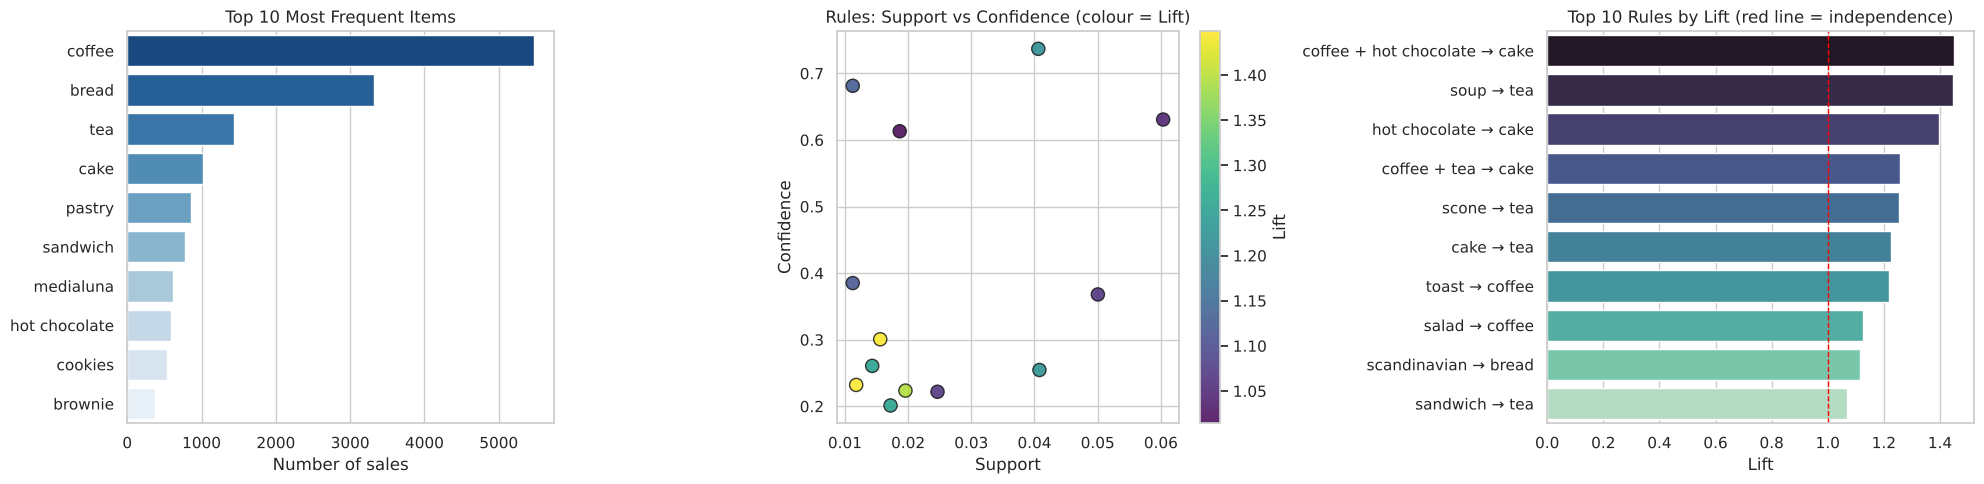

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# A: Top 10 items
top_items = df_clean["Item"].value_counts().head(10)
sns.barplot(x=top_items.values, y=top_items.index, hue=top_items.index, palette="Blues_r", legend=False, ax=axes[0])
axes[0].set(title="Top 10 Most Frequent Items", xlabel="Number of sales", ylabel="")

# B: Support vs confidence, coloured by lift
sc = axes[1].scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=90, alpha=0.85, edgecolor="k")
fig.colorbar(sc, ax=axes[1], label="Lift")
axes[1].set(title="Rules: Support vs Confidence (colour = Lift)", xlabel="Support", ylabel="Confidence")

# C: Top 10 rules by lift
top_rules = rules.head(10).copy()
top_rules["rule"] = top_rules["antecedents_str"] + " → " + top_rules["consequents_str"]
sns.barplot(x="lift", y="rule", hue="rule", data=top_rules, palette="mako", legend=False, ax=axes[2])
axes[2].axvline(1, color="red", ls="--", lw=1)
axes[2].set(title="Top 10 Rules by Lift (red line = independence)", xlabel="Lift", ylabel="")

plt.tight_layout(); plt.show()

---
## 👤 Member 4 — Evaluation Simulator, Export & Streamlit UI
**Objective:** prove the recommender works, ship the results, and provide a user interface.

1. **Evaluation simulator (hold-out hit-rate):** split baskets 80/20, mine rules on the 80% only, then for every test basket hide one item and check if the recommender suggests it.
2. **Export** the rules to `mined_association_rules.csv`.
3. **Streamlit app** (`app.py`) with threshold sliders and a cart simulator.
4. **Live demo** function for the viva.

**Defense pitch:** *"I validated the model with a train/test hit-rate, exported the rules, and built the Streamlit dashboard and live demo."*

In [6]:
# 1. Hold-out evaluation (rules are mined on TRAIN only -> no data leakage)
train = basket_matrix.sample(frac=0.8, random_state=SEED)
test  = basket_matrix.drop(train.index)
_, rules_train = mine_rules(train)

hits, trials = 0, 0
rng = np.random.default_rng(SEED)
for _, row in test.iterrows():
    items = list(row.index[row.values])
    hidden = rng.choice(items)                      # item we try to predict
    cart = [i for i in items if i != hidden]
    recs = recommend_items(cart, rules_train, top_n=TOP_N)
    if not recs.empty:                              # only count carts where a rule fired
        trials += 1
        hits += int(hidden in set(recs["recommended_item"]))

coverage = trials / len(test)
hit_rate = hits / trials if trials else 0
print(f"Train baskets: {len(train):,} | Test baskets: {len(test):,} | Rules (train): {len(rules_train)}")
print(f"Coverage (carts that got a recommendation) : {coverage:.1%}")
print(f"Hit-rate@{TOP_N} (hidden item recommended)       : {hit_rate:.1%}")

Train baskets: 4,414 | Test baskets: 1,103 | Rules (train): 17
Coverage (carts that got a recommendation) : 40.6%
Hit-rate@3 (hidden item recommended)       : 36.6%


In [7]:
# 2. Export rules
RULES_CSV = "mined_association_rules.csv"
export_cols = ["antecedents_str", "consequents_str", "support", "confidence", "lift"]
rules[export_cols].round(4).to_csv(RULES_CSV, index=False)
print(f"✔ Saved {len(rules)} rules to '{RULES_CSV}'")

# 3. Streamlit app (run locally:  pip install streamlit  ->  streamlit run app.py)
app_code = '''import pandas as pd
import streamlit as st

st.set_page_config(page_title="SmartBasket Recommender", page_icon="🛒", layout="wide")
st.title("🛒 SmartBasket: Market Basket Recommender")

@st.cache_data
def load_rules():
    df = pd.read_csv("mined_association_rules.csv")
    df["ante"] = df["antecedents_str"].str.split(" + ", regex=False).apply(frozenset)
    df["cons"] = df["consequents_str"].str.split(" + ", regex=False).apply(frozenset)
    return df

rules_df = load_rules()

st.sidebar.header("Filter rules")
min_conf = st.sidebar.slider("Minimum confidence", 0.10, 1.00, 0.20, 0.05)
min_lift = st.sidebar.slider("Minimum lift", 1.0, 4.0, 1.1, 0.1)
top_n    = st.sidebar.slider("Recommendations to show", 1, 10, 3)

rules_f = rules_df[(rules_df["confidence"] >= min_conf) & (rules_df["lift"] >= min_lift)]
st.sidebar.metric("Rules after filter", len(rules_f))

items = sorted(set().union(*rules_df["ante"]) | set().union(*rules_df["cons"]))

st.subheader("Simulate a customer cart")
cart = set(st.multiselect("Items in the basket:", items, default=[items[0]]))

if cart:
    hits = []
    for _, r in rules_f.iterrows():
        if r["ante"] <= cart:
            for item in r["cons"] - cart:
                hits.append({"Recommended item": item, "Triggered by": r["antecedents_str"],
                             "Confidence": round(r["confidence"], 3), "Lift": round(r["lift"], 3)})
    if hits:
        out = (pd.DataFrame(hits).sort_values(["Lift", "Confidence"], ascending=False)
                 .drop_duplicates("Recommended item").head(top_n))
        st.success("Frequently bought together:")
        st.dataframe(out, hide_index=True, use_container_width=True)
    else:
        st.warning("No rule matches this cart with the current filters.")

st.subheader("All mined rules")
st.dataframe(rules_f[["antecedents_str", "consequents_str", "support", "confidence", "lift"]],
             hide_index=True, use_container_width=True)
'''
with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)
compile(app_code, "app.py", "exec")   # syntax check
print("✔ 'app.py' created (syntax OK).")

✔ Saved 13 rules to 'mined_association_rules.csv'
✔ 'app.py' created (syntax OK).


In [8]:
# 4. Live demo for the viva
def live_defense_demo(cart):
    print(f"\n[Live demo] Customer cart: {cart}")
    res = recommend_items(cart, rules)
    display(res if not res.empty else "No cross-sell rule fires for this cart.")

live_defense_demo(["toast"])
live_defense_demo(["coffee", "hot chocolate"])
live_defense_demo(["soup", "bread"])


[Live demo] Customer cart: ['toast']


,recommended_item,confidence,lift,triggered_by
0,coffee,0.737,1.219,toast



[Live demo] Customer cart: ['coffee', 'hot chocolate']


,recommended_item,confidence,lift,triggered_by
0,cake,0.232,1.449,coffee + hot chocolate



[Live demo] Customer cart: ['soup', 'bread']


,recommended_item,confidence,lift,triggered_by
0,tea,0.301,1.446,soup


---
## ✅ Project Summary
| Stage | Owner | Result |
|---|---|---|
| Cleaning & basket matrix | Member 1 | Clean one-hot matrix of multi-item baskets |
| Apriori & rules | Member 2 | Frequent itemsets and strong rules (lift > 1) |
| Recommender & charts | Member 3 | `recommend_items()` + 3 diagnostic plots |
| Evaluation, export, UI | Member 4 | Hit-rate, CSV, Streamlit app, live demo |